# 03 · Análisis exploratorio (EDA)

**Entrada:** `data/processed/anuncios_limpios.csv`  
**Objetivo:** responder las preguntas de investigación y producir las
figuras del informe.

> Recordatorio: son **precios pedidos**, no precios de transacción. No se
> mezclan USD y CUP sin una tasa documentada.


In [1]:
# Permite importar el paquete src/ desde la raíz del proyecto.
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / 'src').exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /home/bri/proyectos/proyecto-mercado-vehiculos


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import DATA_PROCESSED, FIGURES

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 50)
FIGURES.mkdir(parents=True, exist_ok=True)

ruta = DATA_PROCESSED / 'anuncios_limpios.csv'
if not ruta.exists():
    raise FileNotFoundError(
        'No existe anuncios_limpios.csv. Ejecuta el notebook 02_limpieza.ipynb.'
    )

df = pd.read_csv(ruta)
print('Registros:', len(df))
df.head()

Registros: 9841


,id,categoria,titulo,precio,moneda,provincia,municipio,fecha_publicacion,vistas,n_imagenes,destacado,url,fecha_captura,producto_detectado,relevante,motivo,anio,cilindrada_cc,condicion,tipo,marca,precio_usd
0,58595374,bicicletas,Bicicleta,90.0,USD,La Habana,Habana Vieja,2026-11-05 03:32:30.952+00:00,0,0,False,https://www.revolico.com/item/bicicleta-58595374,2026-11-05 03:33:29+00:00,bicicleta,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,no_especificada,NaN,90.0
1,56789296,motos_electricas,Moto eléctrica,1290.0,USD,La Habana,Centro Habana,2026-11-05 03:27:53.602+00:00,125,1,False,https://www.revolico.com/item/moto-electrica-5...,2026-11-05 03:30:35+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,electrica,NaN,1290.0
2,56634458,motos_combustion,Lifan Lycan,6500.0,USD,La Habana,San Miguel del Padrón,2026-11-05 03:25:41.666+00:00,152,1,False,https://www.revolico.com/item/lifan-lycan-5663...,2026-11-05 03:27:16+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,combustion,Lifan,6500.0
3,58521819,motos_electricas,Topmaq f3 Bateria 55 amperes,2280.0,USD,La Habana,Arroyo Naranjo,2026-11-05 03:25:07.032+00:00,11,1,False,https://www.revolico.com/item/topmaq-f3-bateri...,2026-11-05 03:30:35+00:00,moto,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,electrica,Topmaq,2280.0
4,51700078,bicicletas,💼 BOLSO TRIANGULAR PARA BICICLETA 💼 VARIOS COL...,10.0,USD,La Habana,Plaza,2026-11-05 03:21:53.483+00:00,542,3,False,https://www.revolico.com/item/bolso-triangular...,2026-11-05 03:33:29+00:00,bicicleta,si,producto explícito y categoría compatible,NaN,NaN,no_especificada,no_especificada,NaN,10.0


## 1. Composición de la muestra

¿Cuántos anuncios hay por categoría, provincia y moneda?

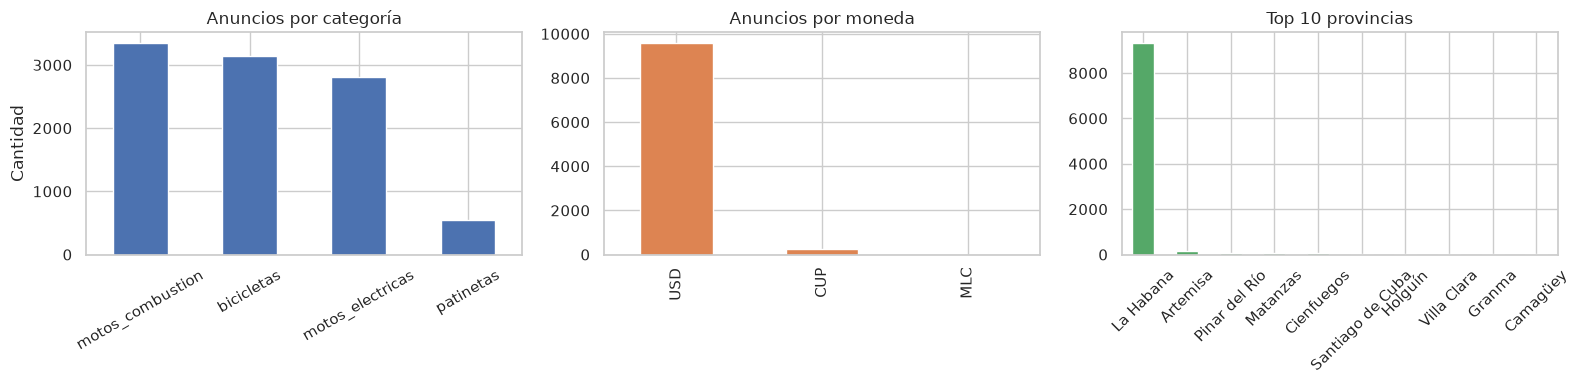

In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

df['categoria'].value_counts().plot(kind='bar', ax=ejes[0], color='#4c72b0')
ejes[0].set_title('Anuncios por categoría')
ejes[0].set_xlabel('')
ejes[0].set_ylabel('Cantidad')
ejes[0].tick_params(axis='x', rotation=30)

df['moneda'].value_counts().plot(kind='bar', ax=ejes[1], color='#dd8452')
ejes[1].set_title('Anuncios por moneda')
ejes[1].set_xlabel('')

df['provincia'].value_counts().head(10).plot(kind='bar', ax=ejes[2], color='#55a868')
ejes[2].set_title('Top 10 provincias')
ejes[2].set_xlabel('')
ejes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES / '01_composicion.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Distribución de precios

Separamos por moneda. La escala logarítmica ayuda porque los precios van
de decenas a miles.

USD: 9589 | CUP: 251


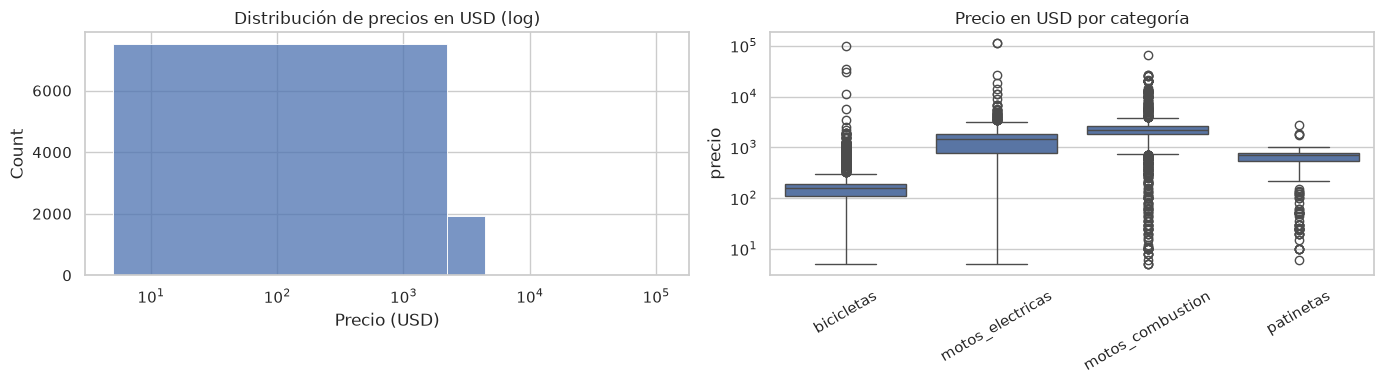

                   count         mean          std  min     25%     50%     75%       max
categoria                                                                                
bicicletas        2936.0   267.499435  2051.784263  5.0   110.0   160.0   190.0  100000.0
motos_combustion  3322.0  2402.498796  2257.154096  5.0  1850.0  2200.0  2600.0   65000.0
motos_electricas  2796.0  1539.611052  3116.891072  5.0   770.0  1485.0  1850.0  111111.0
patinetas          535.0   635.663551   272.883580  6.0   550.0   720.0   780.0    2750.0


In [4]:
usd = df[df['moneda'] == 'USD'].copy()
cup = df[df['moneda'] == 'CUP'].copy()
print('USD:', len(usd), '| CUP:', len(cup))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(usd['precio'], bins=50, ax=ejes[0], color='#4c72b0')
ejes[0].set_xscale('log')
ejes[0].set_title('Distribución de precios en USD (log)')
ejes[0].set_xlabel('Precio (USD)')

sns.boxplot(data=usd, x='categoria', y='precio', ax=ejes[1])
ejes[1].set_yscale('log')
ejes[1].set_title('Precio en USD por categoría')
ejes[1].set_xlabel('')
ejes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(FIGURES / '02_precios.png', dpi=150, bbox_inches='tight')
plt.show()

print(usd.groupby('categoria')['precio'].describe().to_string())

## 3. Precio y características

Relación con el año, la condición y la cilindrada (solo motos).

Anuncios USD con año: 829 de 9589


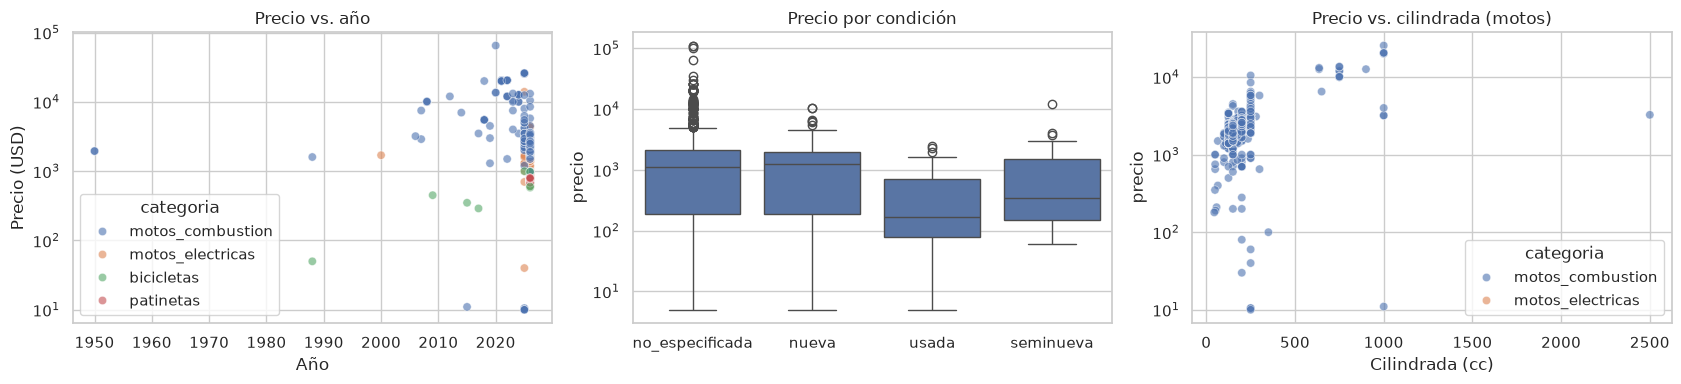

In [5]:
con_anio = usd.dropna(subset=['anio'])
print('Anuncios USD con año:', len(con_anio), 'de', len(usd))

fig, ejes = plt.subplots(1, 3, figsize=(17, 4))

sns.scatterplot(data=con_anio, x='anio', y='precio', hue='categoria', alpha=0.6, ax=ejes[0])
ejes[0].set_yscale('log')
ejes[0].set_title('Precio vs. año')
ejes[0].set_xlabel('Año')
ejes[0].set_ylabel('Precio (USD)')

sns.boxplot(data=usd, x='condicion', y='precio', ax=ejes[1])
ejes[1].set_yscale('log')
ejes[1].set_title('Precio por condición')
ejes[1].set_xlabel('')

motos = usd[usd['categoria'].str.startswith('motos')].dropna(subset=['cilindrada_cc'])
sns.scatterplot(data=motos, x='cilindrada_cc', y='precio', hue='categoria', alpha=0.6, ax=ejes[2])
ejes[2].set_yscale('log')
ejes[2].set_title('Precio vs. cilindrada (motos)')
ejes[2].set_xlabel('Cilindrada (cc)')

plt.tight_layout()
plt.savefig(FIGURES / '03_precio_caracteristicas.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Marcas

Solo consideramos marcas con al menos 10 anuncios para que el precio
mediano sea informativo.

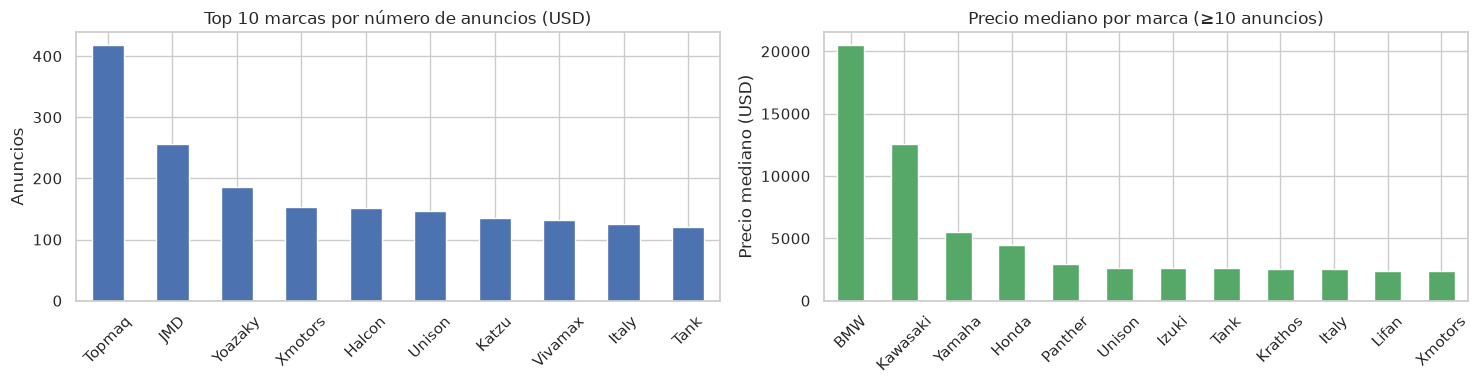

In [6]:
conteo = usd['marca'].value_counts()
top = conteo.head(10)

fig, ejes = plt.subplots(1, 2, figsize=(15, 4))

top.plot(kind='bar', ax=ejes[0], color='#4c72b0')
ejes[0].set_title('Top 10 marcas por número de anuncios (USD)')
ejes[0].set_xlabel('')
ejes[0].set_ylabel('Anuncios')
ejes[0].tick_params(axis='x', rotation=45)

frecuentes = conteo[conteo >= 10].index
mediana = (
    usd[usd['marca'].isin(frecuentes)]
    .groupby('marca')['precio']
    .median()
    .sort_values(ascending=False)
    .head(12)
)
mediana.plot(kind='bar', ax=ejes[1], color='#55a868')
ejes[1].set_title('Precio mediano por marca (≥10 anuncios)')
ejes[1].set_xlabel('')
ejes[1].set_ylabel('Precio mediano (USD)')
ejes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIGURES / '04_marcas.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Geografía

Precio mediano por provincia (solo provincias con ≥ 10 anuncios en USD).

                     anuncios  precio_mediano
provincia                                    
Pinar del Río              63          2000.0
Holguín                    39          1850.0
Isla de la Juventud        11          1850.0
Las Tunas                  12          1840.0
Artemisa                  142          1775.0
Villa Clara                35          1450.0
Mayabeque                  12          1400.0
Granma                     13          1150.0
La Habana                9080          1000.0
Camagüey                   12           635.0
Matanzas                   54           480.0
Santiago de Cuba           45           280.0
Cienfuegos                 51           210.0


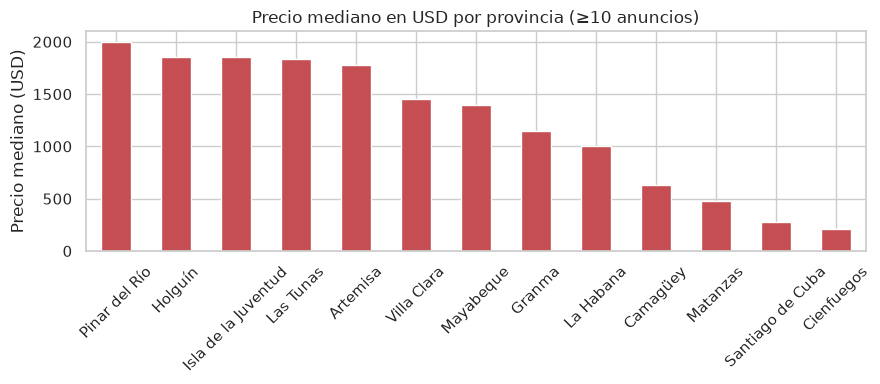

In [7]:
por_provincia = (
    usd.groupby('provincia')
    .agg(anuncios=('id', 'count'), precio_mediano=('precio', 'median'))
    .query('anuncios >= 10')
    .sort_values('precio_mediano', ascending=False)
)
print(por_provincia.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
por_provincia['precio_mediano'].plot(kind='bar', ax=ax, color='#c44e52')
ax.set_title('Precio mediano en USD por provincia (≥10 anuncios)')
ax.set_xlabel('')
ax.set_ylabel('Precio mediano (USD)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(FIGURES / '05_provincias.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Eléctricas vs. combustión

Comparación central del estudio, restringida a motos.

tipo
combustion    3319
electrica     2799


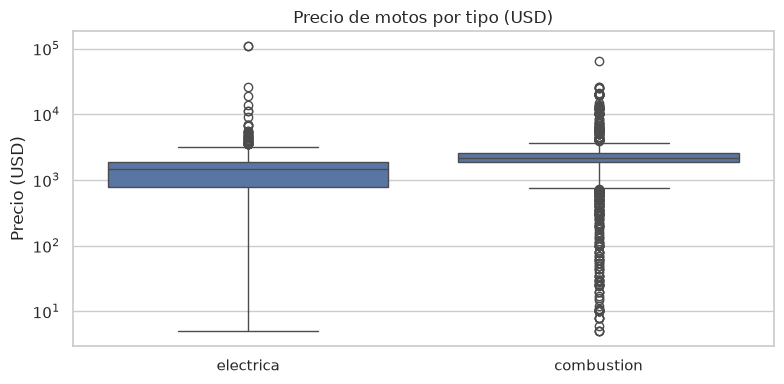

             count         mean          std  min     25%     50%     75%       max
tipo                                                                               
combustion  3319.0  2401.937632  2258.204961  5.0  1850.0  2200.0  2600.0   65000.0
electrica   2799.0  1541.201322  3115.505328  5.0   772.5  1490.0  1850.0  111111.0


In [8]:
motos = usd[usd['categoria'].str.startswith('motos')]
print(motos['tipo'].value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=motos, x='tipo', y='precio', ax=ax)
ax.set_yscale('log')
ax.set_title('Precio de motos por tipo (USD)')
ax.set_xlabel('')
ax.set_ylabel('Precio (USD)')
plt.tight_layout()
plt.savefig(FIGURES / '06_tipo_moto.png', dpi=150, bbox_inches='tight')
plt.show()

print(motos.groupby('tipo')['precio'].describe().to_string())

## 7. Patinetas

Categoría buscada por texto: puede contener ruido. Revisa títulos y decide
si hace falta un filtro adicional.

In [9]:
patinetas = usd[usd['categoria'] == 'patinetas']
print('Patinetas en USD:', len(patinetas))
print(patinetas['precio'].describe().to_string())
print('\nEjemplos de títulos:')
for titulo in patinetas['titulo'].head(15):
    print('-', titulo)

Patinetas en USD: 535
count     535.000000
mean      635.663551
std       272.883580
min         6.000000
25%       550.000000
50%       720.000000
75%       780.000000
max      2750.000000

Ejemplos de títulos:
- Carriola/Patineta para niños
- Scooter infantil, patineta
- 💯PATINETA JMD*
- Set de Protección Infantil de 6 Piezas (Azul) | Nuevo | videojuegoshabana.com/p/1270
- Patineta Eléctrica Xiaomi 4 Lite 2da Gen | 25km/h
- ☎️[contacto] 🛵 Entrega Disponible ⭐Set de Protección Infantil de 6 Piezas ⭐
- Patineta eléctrica G1 nuevas 380 usd
- Scooters patineta infantil de 3 ruedas
- Scooter, patineta o carriola  electrica con amortiguadores
- patineta, carriola electrica nueva en su caja
- Oferta tecnológica: Set de Protección Infantil de 6 Piezas (Azul) | videojuegoshabana.com
- Patineta skate board
- Carriola Patineta Scooter Micro
- Skate Board de uso
- Patineta Infantil


## 8. Hallazgos y siguientes pasos

Escribe aquí 5–7 bullets con los resultados que irán al informe. Cada uno
debe apoyarse en una figura o tabla de este notebook.

- [ ] Composición de la oferta: …
- [ ] Distribución de precios: …
- [ ] Efecto del año/condición: …
- [ ] Marcas dominantes: …
- [ ] Diferencias geográficas: …
- [ ] Eléctricas vs. combustión: …
- [ ] Limitaciones observadas en los datos: …
